In [1]:
from datasets import load_dataset
import nltk
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
import pandas as pd
import seaborn as sns

/Users/ninahew/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/ninahew/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [17]:
# Write a function that takes an integer x and two languages, and returns shared word analysis across x number of wikipedia articles

def analyse_lang(x, lang):
    lang_ds = load_dataset("wikimedia/wikipedia", "20231101.{lang}".format(lang=lang))
    print('dataset ' + '{lang}'.format(lang=lang) + ' loaded')
    # Consider returning number of rows in datasets
    corpus_lang = lang_ds['train']['text'][0:x]
    # print(corpus_lang)
    # Convert to big string
    string_lang = " ".join(corpus_lang)
    tokenized_lang= word_tokenize(string_lang)
    print("{lang}".format(lang=lang) + " after tokenisation")
    print("{lang}".format(lang=lang), " : ", str(len(tokenized_lang)), " words")
    # Remove punctuation, proper nouns and numerical entries
    cleaned_lang = [word for word in tokenized_lang if ((len(word) > 2) and (not(word[0].isupper())) and (not(word.isnumeric())))]
    print("{lang}".format(lang=lang) + " after data cleaning")
    print("{lang}".format(lang=lang), " : ", str(len(cleaned_lang)), " words")
    dict_lang = {}
    for word in cleaned_lang:
        if word not in dict_lang:
            dict_lang[word] = 0
        dict_lang[word] += 1
    return dict_lang


# Generate Shared word analysis
def shared_word_analysis(x,lang_1, lang_2):
    lang_1 = analyse_lang(x,lang_1)
    lang_2 = analyse_lang(x,lang_2)
    lang_1_col_name = 'word_freq_{lang_1}'.format(lang_1=lang_1)
    lang_1_df = pd.DataFrame.from_dict(lang_1, orient='index', columns=[lang_1_col_name])
    # print(lang_1_df.sort_values(by = ['word_freq_{lang_1}'.format(lang_1=lang_1)], ascending= False).head(10))
    lang_2_col_name = 'word_freq_{lang_2}'.format(lang_2=lang_2)
    lang_2_df = pd.DataFrame.from_dict(lang_2, orient='index', columns = [lang_2_col_name])
    # print(lang_2_df.sort_values(by = ['word_freq_{lang_2}'.format(lang_2=lang_2)], ascending= False).head(10))
    shared_words = pd.merge(lang_1_df, lang_2_df, how = 'inner', left_index=True, right_index=True)
    print(str(shared_words.size), " words shared between both languages")
    # sns.set_theme(rc={'figure.figsize':(12,8)})
    # sns.set_theme(style="darkgrid", context="paper")
    # sns.color_palette("Spectral", as_cmap=True)
    # # compare_plot = sns.lineplot(data = shared_words, sort = True)
    # # compare_plot.set_xticklabels(compare_plot.get_xticklabels(), rotation=90)
    # shared_words_top_100 = shared_words.nlargest(100, columns = [lang_1_col_name, lang_2_col_name])
    # print('Top 100 most shared words')
    # print(shared_words_top_100)
    # shared_100_plot = sns.lineplot(data = shared_words_top_100, sort = True)
    # shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)
    return 'hello'
# Intention to return the plot when debugged



In [14]:
# print(analyse_lang(1, 'nl'))

dataset nl loaded
nl after tokenisation
nl  :  3845  words
nl after data cleaning
nl  :  2128  words
{'maart': 1, 'september': 4, 'was': 30, 'een': 75, 'architect': 8, 'stedenbouwkundige': 1, 'naziheerschappij': 1, 'over': 11, '1933-1945': 2, 'hij': 34, 'vanaf': 5, 'rijksarchitect': 1, 'rijksminister': 2, 'van': 152, 'zijn': 45, 'vriendschap': 1, 'met': 30, 'ministerschap': 1, 'gold': 1, 'als': 25, 'machtigste': 1, 'mannen': 1, 'het': 79, 'oorlog': 9, 'werd': 25, 'veroordeeld': 2, 'tot': 12, 'twintig': 2, 'jaar': 4, 'gevangenisstraf': 2, 'gezin': 1, 'waarin': 3, 'geboren': 1, 'wat': 2, 'noemen': 1, 'grossbürgerlich': 1, 'termen': 1, 'gegoede': 1, 'burgerij': 1, 'bourgeoisie': 1, 'vader': 2, 'grootvader': 1, 'waren': 5, 'beiden': 1, 'architecten': 1, 'financiële': 1, 'redenen': 1, 'studeerde': 1, 'aanvankelijk': 1, 'lente': 1, 'zomer': 1, 'zette': 1, 'studie': 1, 'vervolgens': 1, 'voort': 2, 'aan': 23, 'technische': 1, 'hogeschool': 2, 'herfst': 1, 'verhuisde': 1, 'naar': 8, 'probeerde'

In [18]:
shared_word_analysis(1,'af','nl')

dataset af loaded
af after tokenisation
af  :  3158  words
af after data cleaning
af  :  1922  words
dataset nl loaded
nl after tokenisation
nl  :  3845  words
nl after data cleaning
nl  :  2128  words
158  words shared between both languages


'hello'

In [142]:
# Tested bg and mk which are mutually intelligible


datasets loaded
After tokenisation
af : 270255 words
nl : 213125 words
After data cleaning
af : 146069 words
nl : 118362 words
      word_freq_af
die          17870
van           8768
het           4150
wat           2652
word          2061
met           1865
deur          1375
vir           1373
nie           1164
ook           1064
      word_freq_nl
van           7101
het           4810
een           4088
zijn          1932
met           1492
voor          1309
die           1302
door          1143
dat           1055
als           1045
4856 words shared between both languages
Top 100 most shared words
         word_freq_af  word_freq_nl
die             17870          1302
van              8768          7101
het              4150          4810
wat              2652           128
met              1865          1492
...               ...           ...
langs              82            53
dele               82             3
klein              81            32
sommige            80       

/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_22643/855943114.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


Axes(0.125,0.11;0.775x0.77)


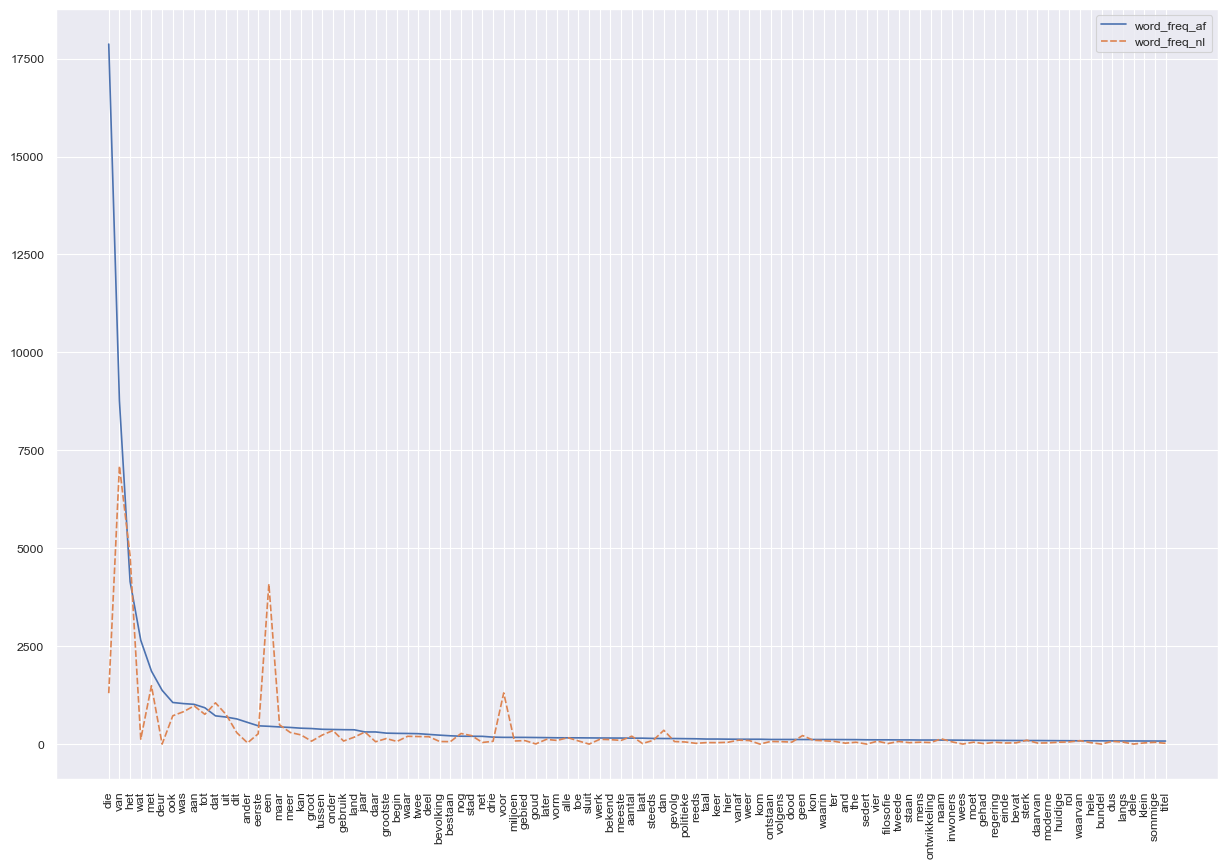

In [149]:
print(shared_word_analysis(100, 'af','nl'))

datasets loaded
After tokenisation
af : 800640 words
nl : 1955121 words
After data cleaning
af : 343488 words
nl : 1066350 words
      word_freq_af
die          42367
van          24462
het           9078
word          5905
wat           5672
met           3623
jaar          3283
was           3265
deur          2997
vir           2815
      word_freq_nl
van          65852
het          43225
een          36257
zijn         16119
met          14170
die          11798
voor         11720
door          9962
dat           9832
als           9339
11748 words shared between both languages
Top 100 most shared words
        word_freq_af  word_freq_nl
die            42367         11798
van            24462         65852
het             9078         43225
word            5905             5
wat             5672          1306
...              ...           ...
waarin           226           857
sterf            226             1
staan            222           416
15de             221             5


/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_22643/855943114.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


Axes(0.125,0.11;0.775x0.77)


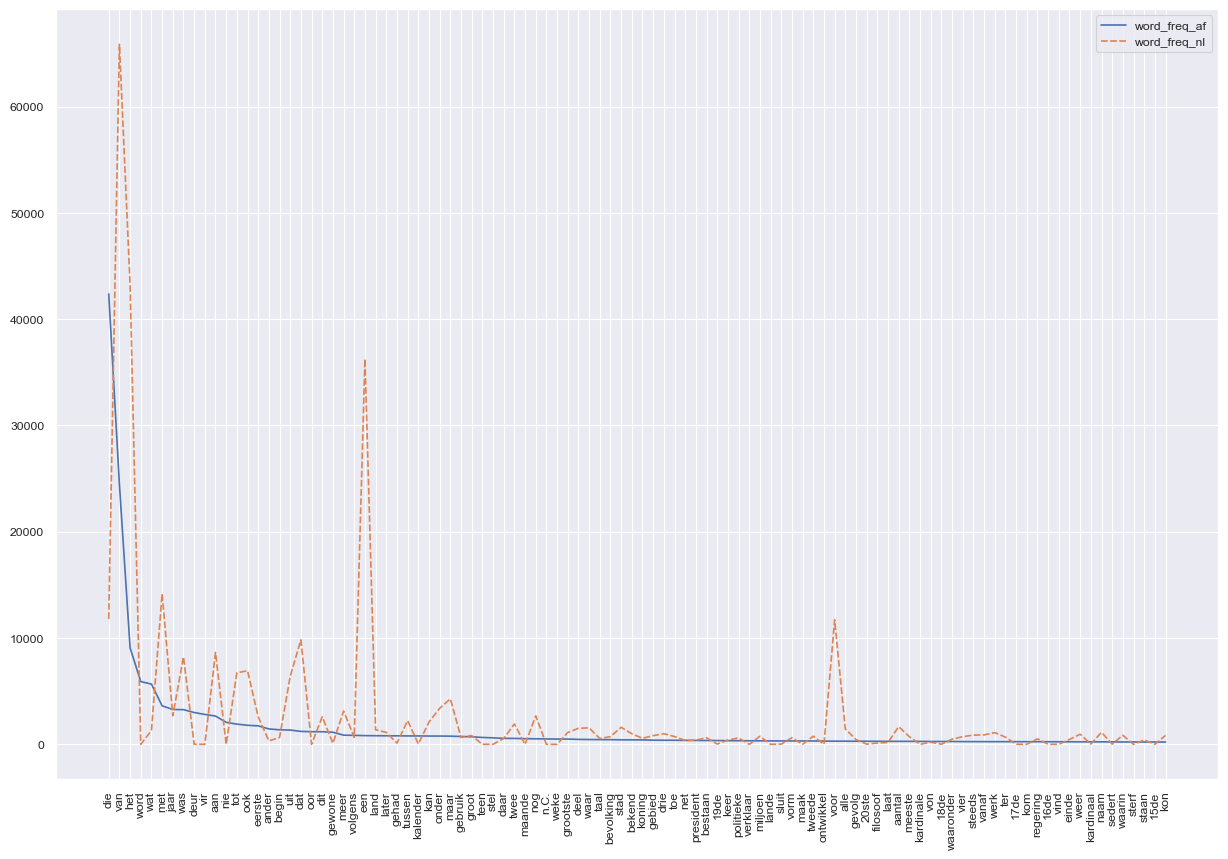

In [150]:
print(shared_word_analysis(1000, 'af','nl'))

datasets loaded
After tokenisation
af : 7359010 words
nl : 14732932 words
After data cleaning
af : 3842404 words
nl : 7394406 words
      word_freq_af
die         469740
van         229829
het         120894
wat          65676
word         57888
met          48178
was          36827
deur         35494
vir          34757
nie          34335
      word_freq_nl
van         467930
het         282297
een         255114
zijn        101477
met          96969
voor         78652
die          74006
door         69472
dat          64951
als          62254
60054 words shared between both languages
Top 100 most shared words
       word_freq_af  word_freq_nl
die          469740         74006
van          229829        467930
het          120894        282297
wat           65676          7803
word          57888            36
...             ...           ...
vier           2681          4173
dus            2665          5567
lewe           2655             2
stel           2654            82
lande   

/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_22643/855943114.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


Axes(0.125,0.11;0.775x0.77)


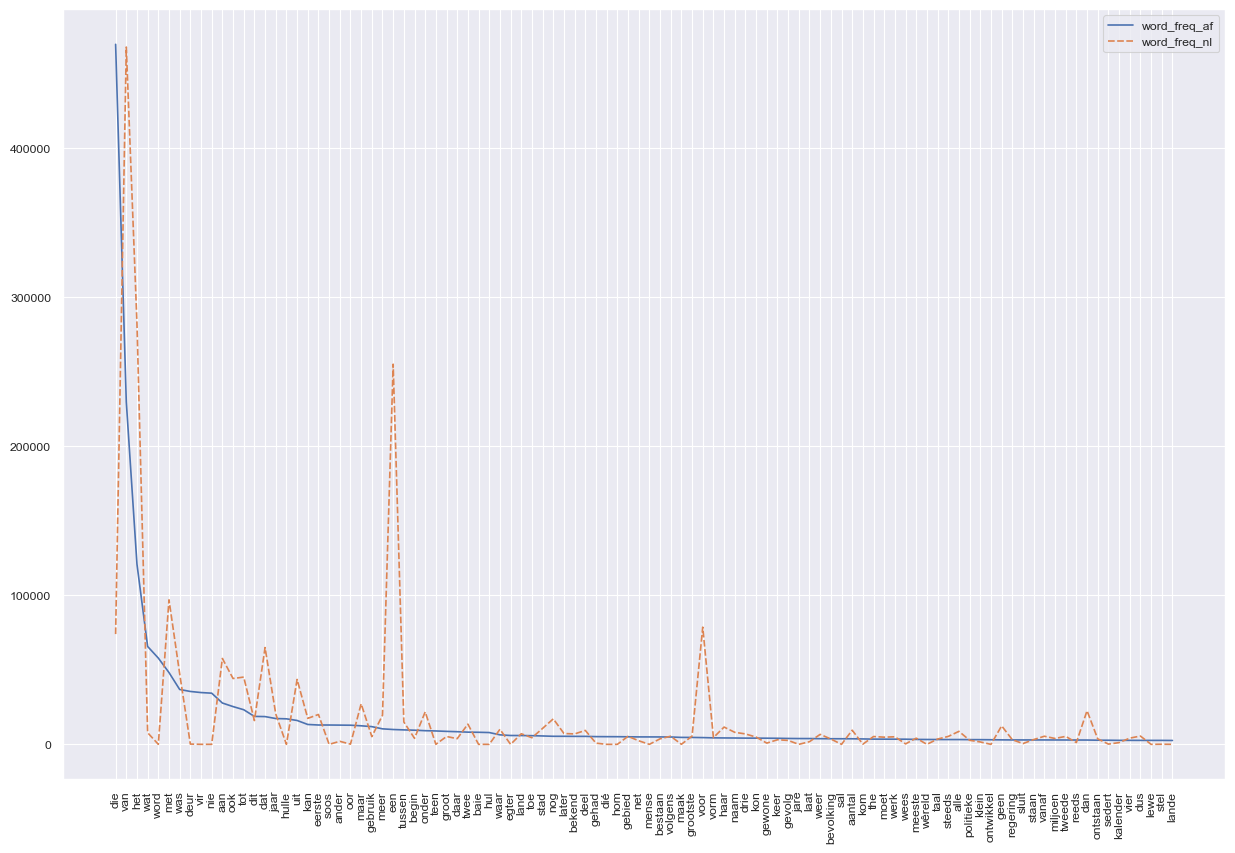

In [151]:
print(shared_word_analysis(10000, 'af','nl'))